# Sprint 1 CV Experiment Template

Loads `data/annotations/manifest.json`, previews each real diagram with its
hand-annotated component boxes and relationships overlaid, and has a stub
cell for running the actual `CVPipeline` (Sprint 2+). This notebook is the
reusable template future sprints extend.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
BACKEND_DIR = REPO_ROOT / "backend"
sys.path.insert(0, str(BACKEND_DIR))

from app.modules.cv_pipeline.dataset_manifest import load_manifest, validate_manifest, DIAGRAMS_DIR

graphs = load_manifest()
problems = validate_manifest(graphs)
print(f"Loaded {len(graphs)} diagrams from the manifest.")
assert not problems, problems
print("Manifest is valid.")

Loaded 10 diagrams from the manifest.
Manifest is valid.


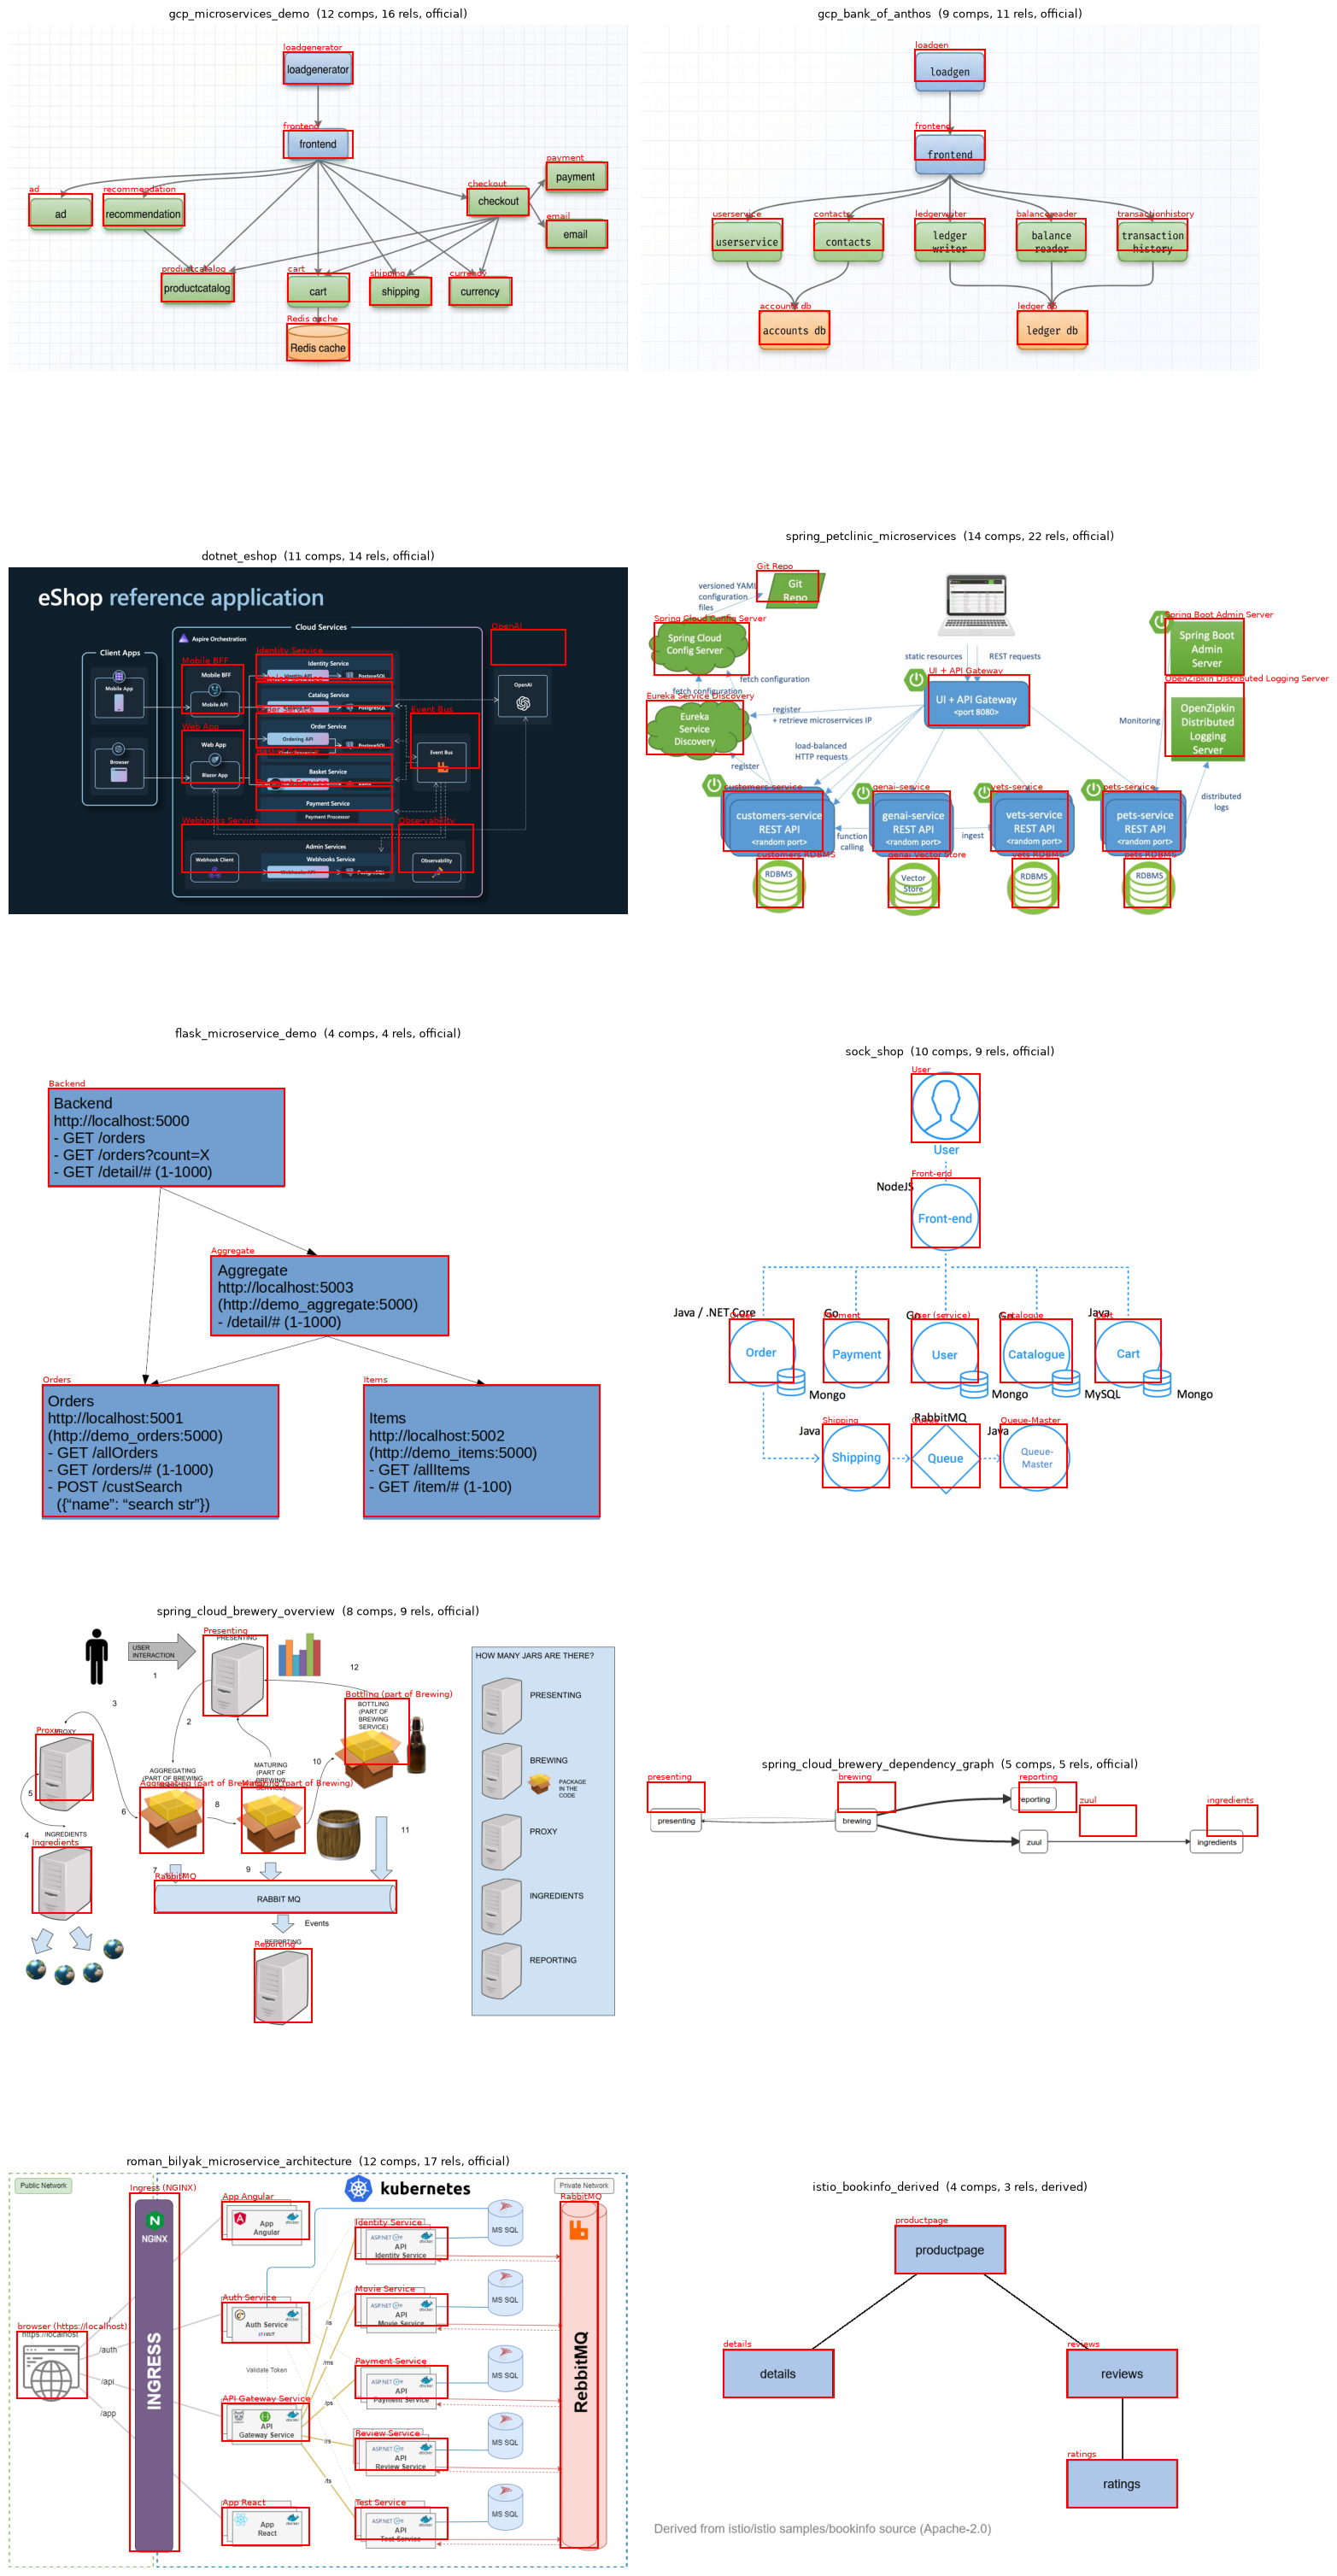

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

fig, axes = plt.subplots(5, 2, figsize=(16, 32))
axes = axes.flatten()

for ax, g in zip(axes, graphs):
    img_path = DIAGRAMS_DIR / Path(g.source).name
    with Image.open(img_path) as im:
        ax.imshow(im)
    for c in g.components:
        if c.bbox is None:
            continue
        w, h = c.bbox.x2 - c.bbox.x1, c.bbox.y2 - c.bbox.y1
        ax.add_patch(patches.Rectangle((c.bbox.x1, c.bbox.y1), w, h, fill=False, edgecolor="red", linewidth=1.5))
        ax.text(c.bbox.x1, c.bbox.y1 - 4, c.name, color="red", fontsize=7)
    provenance = g.metadata["source_repository"]["diagram_provenance"]
    ax.set_title(f"{g.id}  ({len(g.components)} comps, {len(g.relationships)} rels, {provenance})", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Run detector here (stub - Sprint 2/3)

`CVPipeline.analyze()` currently returns empty detections/relationships
without a trained YOLO model and an implemented relationship extractor.
This cell demonstrates the call path future sprints will fill in.

In [3]:
from app.modules.cv_pipeline.pipeline import CVPipeline

pipeline = CVPipeline()
sample = graphs[0]
sample_path = DIAGRAMS_DIR / Path(sample.source).name
result = pipeline.analyze(str(sample_path))
print(f"Ground truth components: {len(sample.components)}")
print(f"Pipeline-detected components: {len(result['components'])}  (expected 0 - no model loaded yet)")

CLIP not available: No module named 'clip'


No YOLO model loaded — returning empty detections.


Ground truth components: 12
Pipeline-detected components: 0  (expected 0 - no model loaded yet)
